# The global statistic Λ and the upper-limit fit

This notebook shows the three statistical tools on a toy dataset: `uuls.lambda_stat` (TS map and
Λ), `uuls.realisations` (inject, Poisson-fake, compute Λ) and `uuls.ulfit` (probit fit of the
detection probability and the upper limit). At the end it compares them with the old
`gwuls.simulate` on identical inputs.

Inputs: no config and no data. The toy dataset and GW map come from `tests/toy.py` (40 × 40 bins of
0.05°, 0.6–20 TeV in 3 bins, flat effective area 10⁵ m², Gaussian PSF σ = 0.1°, flat background,
two runs of 30 min; a Gaussian GW blob of σ = 0.25° with its 90% region as the mask).
Cache entries: `cache/realisations/<key>` for every batch of realisations below.

Imports, figure saver and the seeds. The seed blocks follow the old pipeline: background-only realisations use indices from 0, the fit from 1 000 000, the closure test from 900 000, so no two realisations share a Poisson seed.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

from uuls import lambda_stat, realisations, ulfit, spectra
from uuls.figures import FigureSaver, COLORS

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "tests"))
import toy

figs = FigureSaver("0_tools", "05_lambda_and_ulfit")
SEED_BKG, SEED_FIT, SEED_CLOSURE = 0, 1_000_000, 900_000
N_BKG, CL = 400, 0.95
R_C = 0.1          # correlation radius, deg

## What Λ is

Counts and background are summed over energy and correlated with a top-hat of radius
$r_c = 0.1°$, which gives per bin $n_b$ ON counts and $\mu_b$ expected background counts. The
signed Cash statistic

$$\mathrm{TS}_b = \operatorname{sign}(n_b-\mu_b)\, 2\Big[n_b\ln\frac{n_b}{\mu_b}-(n_b-\mu_b)\Big]$$

is approximately the squared local significance of an excess (positive) or a deficit (negative).
The GW localisation enters through the probability $p_b$ of each bin:

$$\Lambda = \max_{b\in\mathcal{M}} \big(\mathrm{TS}_b + 2\ln p_b\big),$$

with $\mathcal{M}$ the region of interest: the credible region intersected with the observed region
(exposure > 0 inside the safe mask, `lambda_stat.roi`; the whole toy map is observed). Since $\mathrm{TS}_b = 2\ln(\mathcal{L}_1/\mathcal{L}_0)$, Λ picks the
bin where the gamma-ray data prefer a source and the GW data say a source can be, jointly. It is
usually negative because $p_b \ll 1$. The maximum over the region is taken in the data and in every
realisation alike, so the trials factor is in the null distribution.

The toy dataset and GW map. The left panel is the GW probability per bin with the 90% region outlined, the right panel the expected background counts summed over energy (flat by construction).

GW probability in the map 0.999, in the mask 0.900, 362 bins in the mask
expected background counts in the map: 480


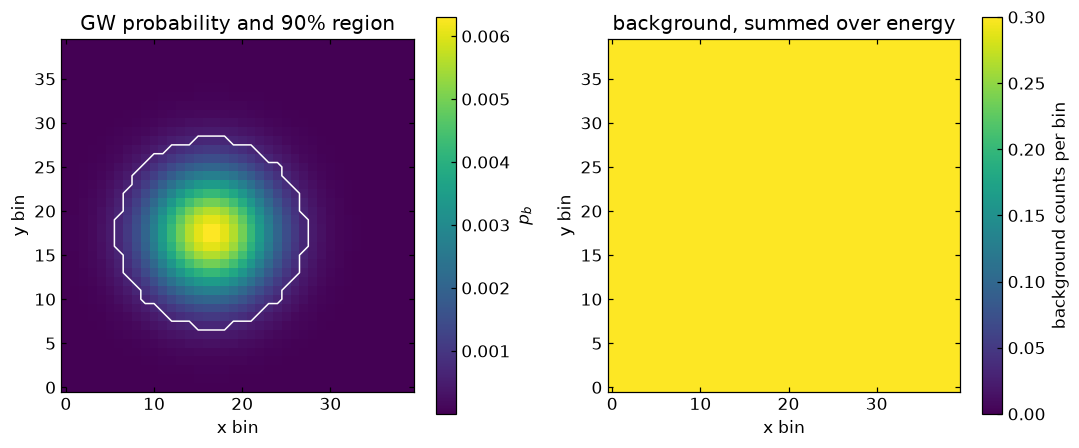

In [2]:
reduced = toy.toy_reduced()
gw = toy.toy_gwmap(reduced.geom)
bkg = lambda_stat.background_cube(reduced.stacked)
print(f"GW probability in the map {gw.prob.sum():.3f}, in the mask {gw.prob[gw.mask].sum():.3f}, "
      f"{gw.mask.sum()} bins in the mask")
print(f"expected background counts in the map: {bkg.sum():.0f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
im = ax[0].imshow(gw.prob, origin="lower")
ax[0].contour(gw.mask, levels=[0.5], colors="w", linewidths=1)
fig.colorbar(im, ax=ax[0], label="$p_b$")
im = ax[1].imshow(bkg.sum(axis=0), origin="lower", vmin=0)
fig.colorbar(im, ax=ax[1], label="background counts per bin")
for a in ax:
    a.set(xlabel="x bin", ylabel="y bin")
ax[0].set_title("GW probability and 90% region")
ax[1].set_title("background, summed over energy")
fig.tight_layout()
figs.save(fig, "toy_inputs")
plt.show()

Two single realisations: a background-only fake and one with a Γ = 2 point source of φ₀ = 4 × 10⁻¹² cm⁻² s⁻¹ TeV⁻¹ injected at a bin drawn from the 90% region. `realisations.realisation` with `keep_maps=True` returns the counts and the TS map along with Λ.

In [3]:
pre = realisations.precompute(reduced, gw, R_C)
inj2d = realisations.PWLInjector2D(gw)
one_bkg = realisations.realisation(reduced, pre, inj2d, 0.0, seed=SEED_BKG, index=0, keep_maps=True)
one_src = realisations.realisation(reduced, pre, inj2d, 4e-12, seed=SEED_FIT, index=0, keep_maps=True)
for name, r in [("background only", one_bkg), ("with source", one_src)]:
    print(f"{name:16s} Lambda = {r['lambda']:7.2f} at bin ({r['lambda_iy']}, {r['lambda_ix']}), "
          f"TS max in mask = {r['tsmax']:6.2f}, expected signal counts = {r['n_signal']:.1f}")
print(f"source injected at bin ({one_src['iy']}, {one_src['ix']})")

background only  Lambda =    0.01 at bin (26, 15), TS max in mask =  13.10, expected signal counts = 0.0
with source      Lambda =   20.09 at bin (16, 25), TS max in mask =  33.19, expected signal counts = 24.2
source injected at bin (16, 25)


The two TS maps on the same colour scale. The white contour is the 90% region, the cross the bin where Λ is reached and the circle the injected position. In the background-only map the largest TS values are fluctuations of a few units; the injected source stands out, and Λ is reached at or next to it.

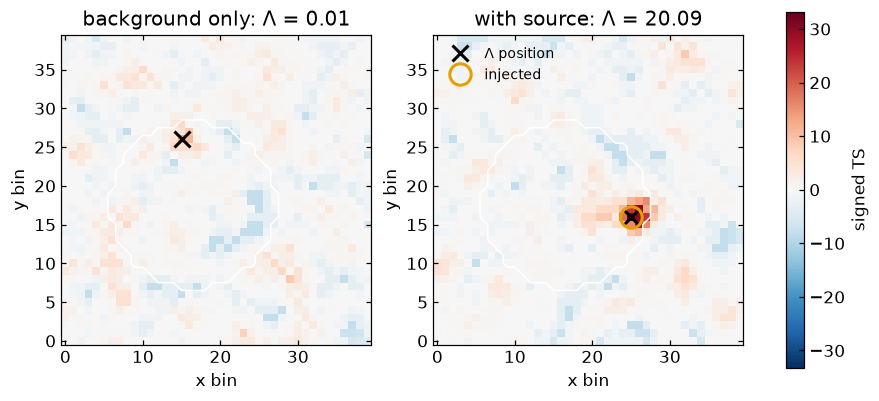

In [4]:
vmax = max(np.abs(one_bkg["ts"]).max(), np.abs(one_src["ts"]).max())
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, r, title in [(ax[0], one_bkg, "background only"), (ax[1], one_src, "with source")]:
    im = a.imshow(r["ts"], origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    a.contour(gw.mask, levels=[0.5], colors="w", linewidths=1)
    a.plot(r["lambda_ix"], r["lambda_iy"], "x", color="k", ms=10, mew=2, label="Λ position")
    a.set(title=f"{title}: Λ = {r['lambda']:.2f}", xlabel="x bin", ylabel="y bin")
ax[1].plot(one_src["ix"], one_src["iy"], "o", mfc="none", mec=COLORS[1], ms=14, mew=2,
           label="injected")
ax[1].legend(loc="upper left", fontsize=9)
fig.colorbar(im, ax=ax, label="signed TS")
figs.save(fig, "ts_maps")
plt.show()

The background-only distribution of Λ, from 400 realisations (cached). The observed Λ of this toy is taken from one more background-only fake, with a seed outside every block, so the toy observation is a pure fluctuation.

In [5]:
lam_bkg = realisations.run(reduced, gw, inj2d, np.zeros(N_BKG), seed=SEED_BKG)["lambda"]
observed = realisations.realisation(reduced, pre, inj2d, 0.0, seed=5_000_000, index=0)
lambda_obs = observed["lambda"]
target, p_value, significance = ulfit.target_lambda(lambda_obs, lam_bkg)
print(f"Lambda_obs = {lambda_obs:.3f}, p = {p_value:.3f}, S = {significance:+.2f}")
print(f"background median {np.median(lam_bkg):.3f}; target Lambda* = {target:.3f}")

[cache] realisations/e96182722845: computed and stored
Lambda_obs = -7.718, p = 0.910, S = -1.34
background median -5.181; target Lambda* = -5.181


Histogram of the background Λ. The target Λ* is the observed value if the data fluctuate up (S ≥ 0) and the background median otherwise, which keeps the limit from beating the median sensitivity.

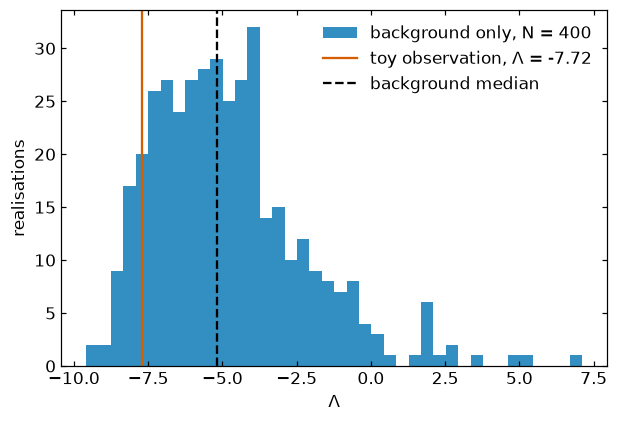

In [6]:
fig, ax = plt.subplots()
ax.hist(lam_bkg, bins=40, color=COLORS[0], alpha=0.8, label=f"background only, N = {N_BKG}")
ax.axvline(lambda_obs, color=COLORS[3], label=f"toy observation, Λ = {lambda_obs:.2f}")
ax.axvline(np.median(lam_bkg), color="k", ls="--", label="background median")
ax.set(xlabel="Λ", ylabel="realisations")
ax.legend()
figs.save(fig, "lambda_background")
plt.show()

## Detection fraction vs strength and the upper limit

Each realisation gets its own amplitude $x_i$ and its own position in the 90% region, and records
$y_i = \mathbf 1[\Lambda_i > \Lambda^\star]$. The detection probability is fitted as

$$f(x) = f_0 + (c - f_0)\,\Phi\!\left(z_0 + \frac{\log_{10}x - \log_{10}x_{\rm UL}}{s}\right),\qquad
z_0 = \Phi^{-1}\!\left(\frac{\mathrm{CL}-f_0}{c-f_0}\right),$$

so $f(x_{\rm UL}) = \mathrm{CL}$ and the limit is itself a fit parameter, with its Monte Carlo
uncertainty from the profile likelihood. The background sample pins $f_0$ in the same likelihood.
`ulfit.adaptive_fit` runs a scout round over the bracket and refine rounds around the transition.
The budget here is small (at most 900 realisations, three rounds); a real limit uses ~6000.

In [7]:
batch = realisations.batch_function(reduced, gw, inj2d, SEED_FIT, verbose=False)
res = ulfit.adaptive_fit(batch, 2e-13, 2e-11, lambda_obs, lam_bkg, cl=CL, n_scout=300,
                         n_refine=300, precision=0.03, max_sims=900, max_rounds=3,
                         design_seed=SEED_FIT, label="phi0", unit="cm-2 s-1 TeV-1")
print()
print(res.report("phi0", "cm-2 s-1 TeV-1"))

[  scout] N =   300, total 300, fit on 300: phi0_UL = 2.7919e-12 cm-2 s-1 TeV-1 [2.3797e-12, 3.3943e-12] (+-0.0771 dex), width 0.277 dex, f0 0.499, c 1.0000


[round 1] N =   300, total 600, fit on 586: phi0_UL = 2.5437e-12 cm-2 s-1 TeV-1 [2.3207e-12, 2.8497e-12] (+-0.0446 dex), width 0.181 dex, f0 0.508, c 1.0000


[round 2] N =   300, total 900, fit on 777: phi0_UL = 2.8375e-12 cm-2 s-1 TeV-1 [2.6118e-12, 3.1262e-12] (+-0.0390 dex), width 0.246 dex, f0 0.517, c 1.0000
  stopped after 3 round(s) and 900 realisations with a 1 sigma half-width of 0.0390 dex > precision 0.03 dex

phi0_UL = 2.8375e-12 cm-2 s-1 TeV-1  (CL 0.95, target Lambda -5.181)
  1 sigma    -8.0% /  +10.2%   [2.612e-12, 3.126e-12] cm-2 s-1 TeV-1
  2 sigma   -14.5% /  +23.3%   [2.426e-12, 3.499e-12] cm-2 s-1 TeV-1
  width 0.246 +- 0.045 dex, f0 0.517 +- 0.026 (background only 0.500), ceiling 1.0000 +- 0.0000
  goodness of fit chi2/ndof = 10.7/5 (p = 0.06); 3 round(s), 900 realisations, converged False


The same limit as photon and energy flux in 0.6–20 TeV; the MC interval carries over unchanged because every flux quantity is proportional to φ₀.

In [8]:
print(spectra.flux_point(res.x_ul, (0.6 * u.TeV, 20 * u.TeV)))

phi0        = 2.838e-12 cm-2 s-1 TeV-1 @ 1.00 TeV
photon flux = 4.587e-12 cm-2 s-1        [0.60 TeV-20.00 TeV]
energy flux = 1.594e-11 erg cm-2 s-1    [0.60 TeV-20.00 TeV]
E2 dN/dE    = 4.546e-12 erg cm-2 s-1 @ 3.46 TeV


Left: every realisation's outcome (ticks at 0 and 1), the fraction above Λ* in equal-count groups, and the fitted curve with its 1σ and 2σ bands; the limit is where the curve crosses CL. Right: the profile likelihood of log₁₀ φ₀,UL, whose crossings of 1 and 4 give the 1σ and 2σ intervals.

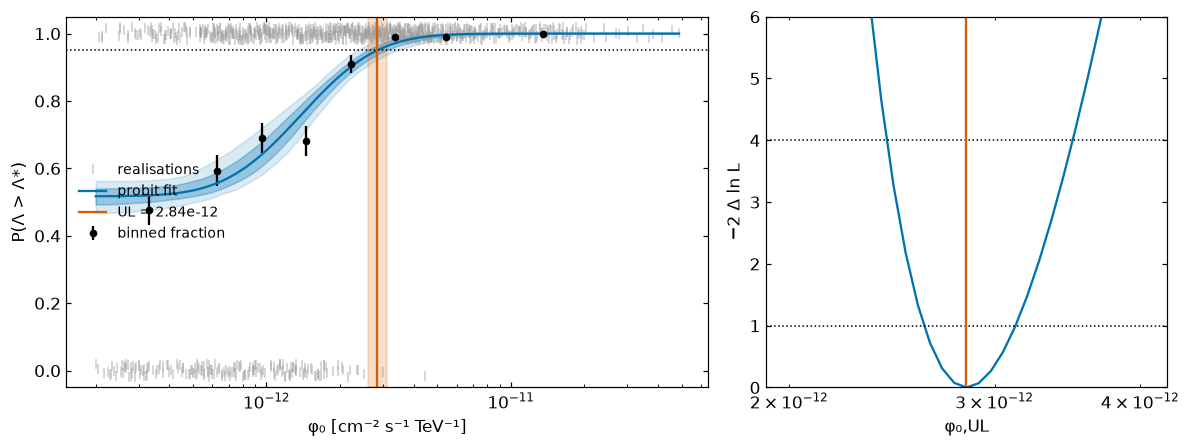

In [9]:
x, y = res.samples["x"], res.samples["lambda"] > res.target
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
a = ax[0]
a.plot(x, y + np.random.default_rng(0).uniform(-0.02, 0.02, x.size), "|", color="0.6", ms=6,
       alpha=0.5, label="realisations")
a.errorbar(res.binned["x"], res.binned["frac"], yerr=res.binned["err"], fmt="o", color="k",
           ms=4, label="binned fraction")
cx = res.curve["x"]
if "p_lo_2sigma" in res.curve:
    a.fill_between(cx, res.curve["p_lo_2sigma"], res.curve["p_hi_2sigma"], color=COLORS[0], alpha=0.15)
    a.fill_between(cx, res.curve["p_lo_1sigma"], res.curve["p_hi_1sigma"], color=COLORS[0], alpha=0.3)
a.plot(cx, res.curve["p"], color=COLORS[0], label="probit fit")
a.axhline(CL, color="k", ls=":", lw=1)
a.axvline(res.x_ul, color=COLORS[3], label=f"UL = {res.x_ul:.2e}")
a.axvspan(res.x_ul_lo_1sigma, res.x_ul_hi_1sigma, color=COLORS[3], alpha=0.2)
a.set(xscale="log", xlabel="φ₀ [cm⁻² s⁻¹ TeV⁻¹]", ylabel="P(Λ > Λ*)", ylim=(-0.05, 1.05))
a.legend(loc="center left", fontsize=9)
b = ax[1]
b.plot(res.profile["x"], res.profile["delta_2nll"], color=COLORS[0])
for lev in (1, 4):
    b.axhline(lev, color="k", ls=":", lw=1)
b.axvline(res.x_ul, color=COLORS[3])
b.set(xscale="log", xlabel="φ₀,UL", ylabel="−2 Δ ln L", ylim=(0, 6))
fig.tight_layout()
figs.save(fig, "ul_fit")
plt.show()

Closure test: 300 fresh realisations at the quoted limit, with independent seeds. The fraction above Λ* should be CL within the binomial error combined with the limit's own uncertainty mapped through the curve.

In [10]:
lam_closure = realisations.run(reduced, gw, inj2d, np.full(300, res.x_ul), seed=SEED_CLOSURE,
                               verbose=False)["lambda"]
cp = ulfit.closure_pull(res, lam_closure)
print(f"fraction above target at the UL: {cp['frac']:.3f} +- {cp['err_tot']:.3f} "
      f"(binomial {cp['err']:.3f}, from the UL {cp['err_ul']:.3f}); pull {cp['pull']:+.2f}")

fraction above target at the UL: 0.943 +- 0.019 (binomial 0.013, from the UL 0.014); pull -0.35


## Regression against `gwuls.simulate`

The new tools must give the old numbers on identical inputs. The checks below call the old
functions from `../gw-gamma-global-uls` (read-only) on the same arrays and seeds:

1. the TS map and Λ of the background-only fake above, against `_TSEngine` (gammapy's
   `ExcessMapEstimator` internals);
2. six realisations at fixed positions and amplitudes, against `_simulate_realisations`;
3. the whole adaptive fit above, against `_fit_ul`, feeding the old loop the Λ values the new one
   simulated (both loops ask for the same strengths when their fits agree);
4. the spectral conversions, against the old functions.

In [11]:
from gammapy.estimators import ExcessMapEstimator
from gammapy.maps import Map
from astropy.coordinates import SkyCoord

with warnings.catch_warnings():      # the old package imports lal, which warns about stdout
    warnings.simplefilter("ignore")
    REF = toy.reference_simulate()
ds = reduced.stacked
ds.counts = Map.from_geom(ds.counts.geom, data=one_bkg["counts"])
engine = REF._TSEngine(ds, ExcessMapEstimator(correlation_radius=R_C * u.deg), gw.prob, gw.mask, 1.0)
ts_old, ts2_old = engine.ts_maps(engine.counts_statistics())
old = engine.lambda_from(ts_old, ts2_old)
print(f"1. TS map: max |new - old| = {np.abs(one_bkg['ts'] - ts_old).max():.1e}; "
      f"Lambda new {one_bkg['lambda']:.10f}, old {old['lambda_data']:.10f}")

ra, dec = realisations.bin_centres(gw.geom)
iy, ix = realisations.sample_sky_2d(gw, 6, np.random.default_rng(1))
amps = np.array([0.0, 1e-12, 2e-12, 4e-12, 8e-12, 1.6e-11])
coords = SkyCoord(ra=ra[iy, ix] * u.deg, dec=dec[iy, ix] * u.deg)
old6 = REF._simulate_realisations(engine, coords, amps, range(6), 2.0, REF.E_REF, 123,
                                  "model-simulated", False, False, False)
ds.models = None
lookup = dict(zip(amps, coords))
fixed = lambda rng, s: realisations.Injection(lookup[s], realisations._pwl(s, 2.0, 1.0))
new6 = realisations.simulate(reduced, gw, fixed, amps, seed=123)
print(f"2. six realisations: max |Lambda new - old| = "
      f"{np.abs(new6['lambda'] - np.asarray(old6['lambda_data'])).max():.1e}")
print("   Lambda:", np.round(new6["lambda"], 4))

1. TS map: max |new - old| = 0.0e+00; Lambda new 0.0116334460, old 0.0116334460


2. six realisations: max |Lambda new - old| = 0.0e+00
   Lambda: [ -4.2227  -7.3188   2.0099  11.8043  22.8961 131.4928]


In [12]:
stored = dict(zip(res.samples["x"], res.samples["lambda"]))
replay = lambda xs, r, first: np.array([stored[v] for v in xs])
old_fit = REF._fit_ul(replay, 2e-13, 2e-11, CL, res.target, lam_bkg, n_scout=300, n_refine=300,
                      precision=0.03, max_sims=900, max_rounds=3, design_seed=SEED_FIT, verbose=False)
print("3. adaptive fit, new vs old:")
for key in ("x_ul", "x_ul_lo_1sigma", "x_ul_hi_1sigma", "x_ul_lo_2sigma", "x_ul_hi_2sigma",
            "width_dex", "f0", "ceiling"):
    a, b = getattr(res, key), old_fit[key]
    print(f"   {key:15s} {a:.10e}  {b:.10e}  rel. diff {abs(a / b - 1):.1e}")

with warnings.catch_warnings():      # gammapy's Gamma = 2 energy flux also evaluates 1/(2-Gamma)
    warnings.simplefilter("ignore", RuntimeWarning)
    rows = spectra.check_conversions(verbose=False)
band = (0.6 * u.TeV, 20 * u.TeV)
d = np.array([40.0, 400.0, 1400.0]) * u.Mpc
diff = max(abs(spectra.pwl_energy_flux(res.x_ul, band, g).value / REF.pwl_energy_flux(res.x_ul, band, g).value - 1)
           for g in (1.5, 2.0, 2.5))
diff_l = np.max(np.abs(spectra.amplitude_from_luminosity(1e45, d, band, index=2.5, redshift="auto")
                       / REF.amplitude_from_luminosity(1e45, d, band, index=2.5, redshift="auto") - 1))
print(f"4. spectra: {sum(r[-1] for r in rows)}/{len(rows)} self-checks pass; "
      f"max rel. diff to the old code: energy flux {diff:.1e}, amplitude from L {diff_l:.1e}")

3. adaptive fit, new vs old:
   x_ul            2.8375492588e-12  2.8375492588e-12  rel. diff 0.0e+00
   x_ul_lo_1sigma  2.6118487917e-12  2.6118487917e-12  rel. diff 0.0e+00
   x_ul_hi_1sigma  3.1262398879e-12  3.1262398879e-12  rel. diff 0.0e+00
   x_ul_lo_2sigma  2.4257173619e-12  2.4257173619e-12  rel. diff 0.0e+00
   x_ul_hi_2sigma  3.4993108638e-12  3.4993108638e-12  rel. diff 0.0e+00
   width_dex       2.4645109772e-01  2.4645109772e-01  rel. diff 0.0e+00
   f0              5.1703743207e-01  5.1703743207e-01  rel. diff 0.0e+00
   ceiling         9.9999999918e-01  9.9999999918e-01  rel. diff 0.0e+00


4. spectra: 35/35 self-checks pass; max rel. diff to the old code: energy flux 0.0e+00, amplitude from L 0.0e+00


## Outputs

Figures in `outputs/figures/0_tools/05_lambda_and_ulfit/`: `toy_inputs`, `ts_maps`,
`lambda_background`, `ul_fit` (png and pdf). Cache entries under `cache/realisations/`: the
background block, the fit rounds and the closure block. No result files: the toy numbers are
for illustration only.